## Implementation of Linear regression using python

In [1]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt

## Load the dataset

In [2]:
DF1=pd.read_csv("weight-height.csv")
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


### Standardize numerical features

In [3]:
col = ["Height","Weight"]
S1=MinMaxScaler()
DF1[col] = S1.fit_transform(DF1[col])
DF1.head()


,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [6]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
X.shape
Y.shape

(10000, 1)

## Split the data into training and test set

In [7]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [8]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [34]:
## Training  Linear regressions model 

In [9]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [10]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


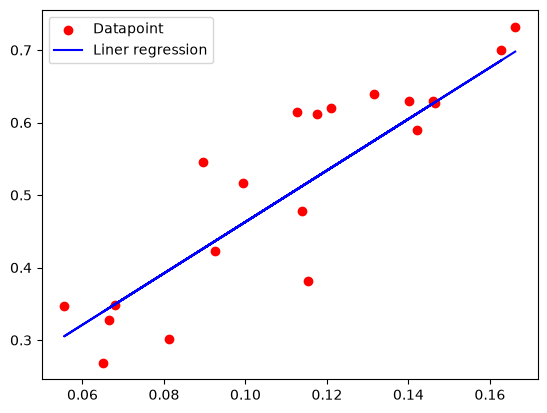

In [11]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [38]:
## Load the Height and weight  to indipendent and dependent variable 

In [13]:
df2=pd.read_csv("weight-height.csv")
x=df2["Height"].values.reshape(-1,1)
X.shape
Y=df2["Weight"].values
print(X.shape)
print(Y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [14]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [41]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [49]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)
print(y_pred.shape)

(10000, 2)
(2, 10000)
(10000,)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [ ]:
for i in range(iterations):
    y_pred = np.dot(X,thetha)
    mse = mean_squared_error(Y,y_pred)
    mseh.append(mse)
    print(f"ilterations {i+1} : MSE = {mse}")
    gradient = np.dot(X.T,(y_pred-y))/len(y)
    thetha-=learningrate * gradient

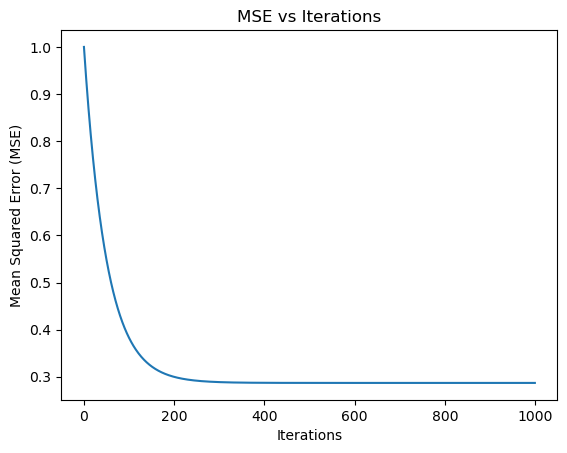

In [44]:
# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

In [2]:
# ---------- 1. Import libraries ----------
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# ---------- 2. Load the dataset ----------
df = pd.read_csv("Food_Delivery_Times.csv")
print(df.head())
print(df.info())

# Check categories and missing values
print(df["Traffic_Level"].unique())
print(df["Weather"].unique())
print(df.isnull().sum())

# Drop rows with missing values in the columns we use
cols = ["Distance_km", "Preparation_Time_min", "Traffic_Level", "Weather", "Delivery_Time_min"]
df = df[cols].dropna()

# ---------- 3. Categorical encoding ----------
# Traffic_Level is ordinal (Low < Medium < High) -> Ordinal / Label encoding
traffic_map = {"Low": 1, "Medium": 2, "High": 3}
df["Traffic_Level"] = df["Traffic_Level"].map(traffic_map)

# Weather is nominal (no natural order) -> One-Hot encoding
df = pd.get_dummies(df, columns=["Weather"], drop_first=True, dtype=int)

print(df.head())

# ---------- 4. Define independent (X) and dependent (y) variables ----------
X = df.drop("Delivery_Time_min", axis=1)   # Distance, Prep time, Traffic, Weather dummies
y = df["Delivery_Time_min"]

# ---------- 5. Train-test split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------- 6. Fit the Linear Regression model ----------
model = LinearRegression()
model.fit(X_train, y_train)

# ---------- 7. Model parameters ----------
print("Intercept:", model.intercept_)
coef_df = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_})
print(coef_df)

# ---------- 8. Predictions and evaluation ----------
y_pred = model.predict(X_test)

print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

   Order_ID  Distance_km Weather Traffic_Level Time_of_Day Vehicle_Type  \
0       522         7.93   Windy           Low   Afternoon      Scooter   
1       738        16.42   Clear        Medium     Evening         Bike   
2       741         9.52   Foggy           Low       Night      Scooter   
3       661         7.44   Rainy        Medium   Afternoon      Scooter   
4       412        19.03   Clear           Low     Morning         Bike   

   Preparation_Time_min  Courier_Experience_yrs  Delivery_Time_min  
0                    12                     1.0                 43  
1                    20                     2.0                 84  
2                    28                     1.0                 59  
3                     5                     1.0                 37  
4                    16                     5.0                 68  
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Cou

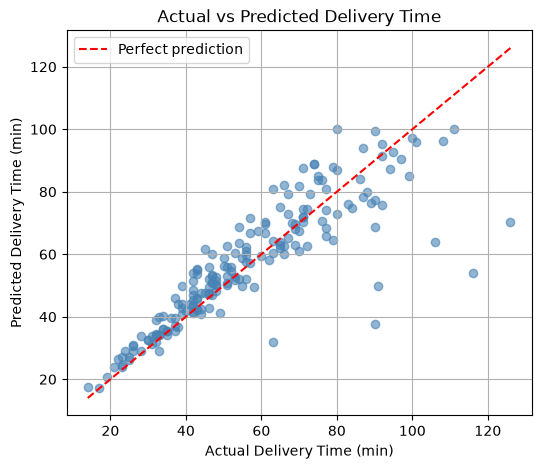

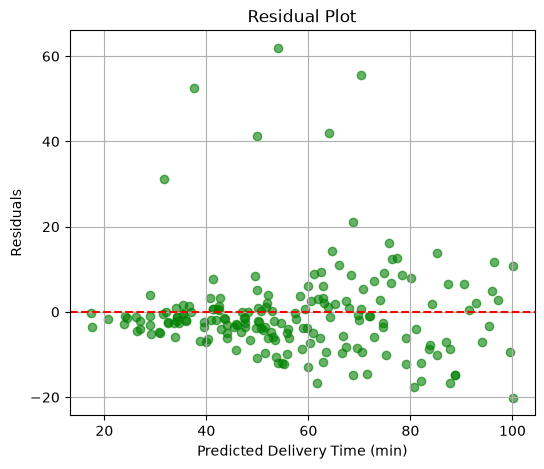

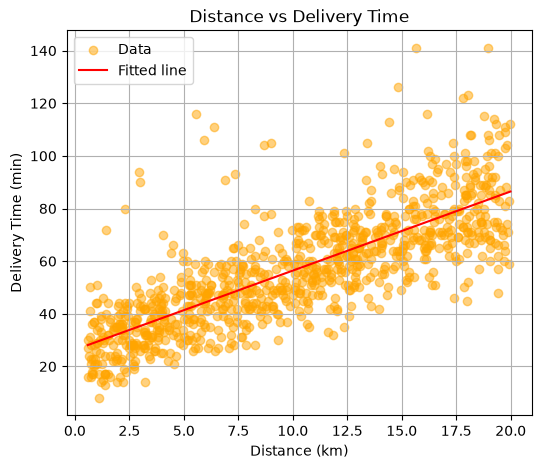

In [3]:
import matplotlib.pyplot as plt

# ---------- Graph 1: Actual vs Predicted ----------
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color="steelblue")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual Delivery Time (min)")
plt.ylabel("Predicted Delivery Time (min)")
plt.title("Actual vs Predicted Delivery Time")
plt.legend()
plt.grid(True)
plt.show()

# ---------- Graph 2: Residual plot ----------
residuals = y_test - y_pred
plt.figure(figsize=(6, 5))
plt.scatter(y_pred, residuals, alpha=0.6, color="green")
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Delivery Time (min)")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid(True)
plt.show()

# ---------- Graph 3: Regression line for Distance alone (simple view) ----------
plt.figure(figsize=(6, 5))
plt.scatter(df["Distance_km"], df["Delivery_Time_min"], alpha=0.5, color="orange", label="Data")
slope, intercept = np.polyfit(df["Distance_km"], df["Delivery_Time_min"], 1)
x_line = np.linspace(df["Distance_km"].min(), df["Distance_km"].max(), 100)
plt.plot(x_line, slope * x_line + intercept, color="red", label="Fitted line")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (min)")
plt.title("Distance vs Delivery Time")
plt.legend()
plt.grid(True)
plt.show()